In [16]:
from google.colab import files
uploaded = files.upload()

Saving merged_dataset.csv to merged_dataset.csv


In [17]:
import pandas as pd
import numpy as np

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
df = pd.read_csv("merged_dataset.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (18115, 28)
  interaction_id user_id         timestamp day_of_week time_of_day  \
0        I000001   U0424  2026-07-01 00:39   Wednesday       night   
1        I000002   U0250  2026-07-01 00:43   Wednesday       night   
2        I000003   U0222  2026-07-01 01:34   Wednesday       night   
3        I000004   U0316  2026-07-01 02:24   Wednesday       night   
4        I000005   U0142  2026-07-01 02:31   Wednesday       night   

          mood  mood_intensity  energy_level activity_id      source  ...  \
0      anxiety               5             3        A002  rule_based  ...   
1      anxiety               3             4        A064      random  ...   
2  frustration               4             3        A061      random  ...   
3   loneliness               2             3        A018  rule_based  ...   
4       stress               4             3        A033  rule_based  ...   

  max_duration_pref  usual_energy              activity_title  \
0                10     

In [20]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18115 entries, 0 to 18114
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   interaction_id        18115 non-null  object 
 1   user_id               18115 non-null  object 
 2   timestamp             18115 non-null  object 
 3   day_of_week           18115 non-null  object 
 4   time_of_day           18115 non-null  object 
 5   mood                  18115 non-null  object 
 6   mood_intensity        18115 non-null  int64  
 7   energy_level          18115 non-null  int64  
 8   activity_id           18115 non-null  object 
 9   source                18115 non-null  object 
 10  action                18115 non-null  object 
 11  rating                9049 non-null   float64
 12  helpful               18115 non-null  int64  
 13  split                 18115 non-null  object 
 14  age_group             18115 non-null  object 
 15  experience_level   

In [21]:
df.describe()

,mood_intensity,energy_level,rating,helpful,max_duration_pref,usual_energy,energy_required,duration_min,difficulty,needs_privacy
count,18115.000000,18115.000000,9049.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000
mean,3.005244,2.875021,3.424688,0.248247,10.981231,3.027105,1.262048,6.411041,1.310847,0.301794
std,1.142988,1.352620,1.025909,0.432008,5.970159,1.130828,0.534710,4.591093,0.539109,0.459049
min,1.000000,1.000000,1.000000,0.000000,5.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,2.000000,2.000000,3.000000,0.000000,5.000000,2.000000,1.000000,4.000000,1.000000,0.000000
50%,3.000000,3.000000,3.000000,0.000000,10.000000,3.000000,1.000000,5.000000,1.000000,0.000000
75%,4.000000,4.000000,4.000000,0.000000,20.000000,4.000000,1.000000,10.000000,2.000000,1.000000
max,5.000000,5.000000,5.000000,1.000000,20.000000,5.000000,3.000000,20.000000,3.000000,1.000000


In [22]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print(df["helpful"].value_counts())

rating    9066
dtype: int64
helpful
0    13618
1     4497
Name: count, dtype: int64


In [23]:
print(df.groupby("action")["rating"].apply(lambda x: round(x.notna().mean(), 2)))

action
completed    1.0
dropped      0.0
skipped      0.0
Name: rating, dtype: float64


In [24]:
print(pd.crosstab(df["action"], df["helpful"]))

helpful       0     1
action               
completed  4552  4497
dropped    2530     0
skipped    6536     0


In [25]:
helpful_rate = df["helpful"].mean()
print("Helpful rate:", round(helpful_rate * 100, 2), "%")
print("Accuracy if model always says 0:", round((1 - helpful_rate) * 100, 2), "%")

Helpful rate: 24.82 %
Accuracy if model always says 0: 75.18 %


In [26]:
print(df.groupby("source")["helpful"].mean().round(3))

source
random        0.137
rule_based    0.362
Name: helpful, dtype: float64


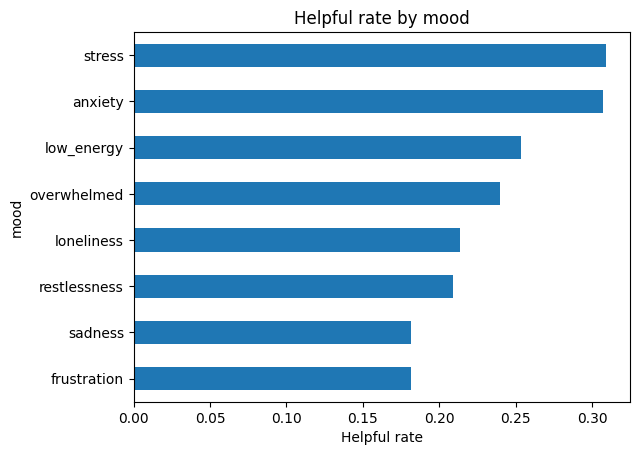

In [27]:
df.groupby("mood")["helpful"].mean().sort_values().plot(kind="barh", title="Helpful rate by mood")
plt.xlabel("Helpful rate")
plt.show()

In [28]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [29]:
print("Unknown or blank values:")
for col in df.select_dtypes(include="object").columns:
    print(col, (df[col].isin(["?", "Unknown", ""])).sum())

Unknown or blank values:
interaction_id 0
user_id 0
timestamp 0
day_of_week 0
time_of_day 0
mood 0
activity_id 0
source 0
action 0
split 0
age_group 0
experience_level 0
pref_category_1 0
pref_category_2 0
activity_title 0
activity_category 0
activity_description 0
target_moods 0


In [30]:
print("Mood values:", sorted(df["mood"].unique()))
print("Time of day values:", sorted(df["time_of_day"].unique()))
print("Action values:", sorted(df["action"].unique()))

Mood values: ['anxiety', 'frustration', 'loneliness', 'low_energy', 'overwhelmed', 'restlessness', 'sadness', 'stress']
Time of day values: ['afternoon', 'evening', 'morning', 'night']
Action values: ['completed', 'dropped', 'skipped']


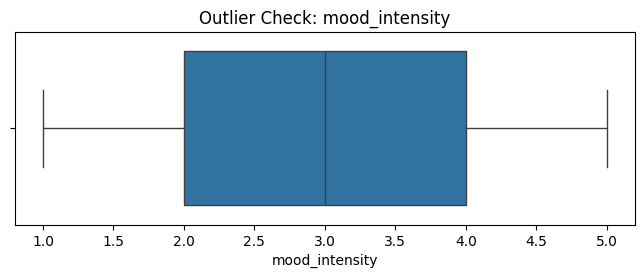

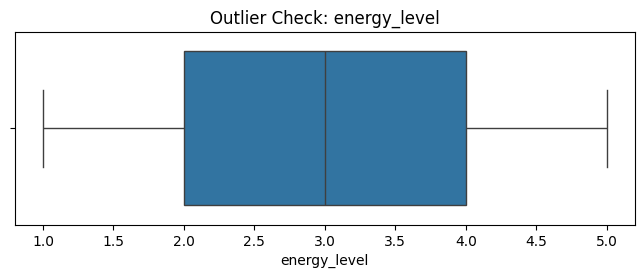

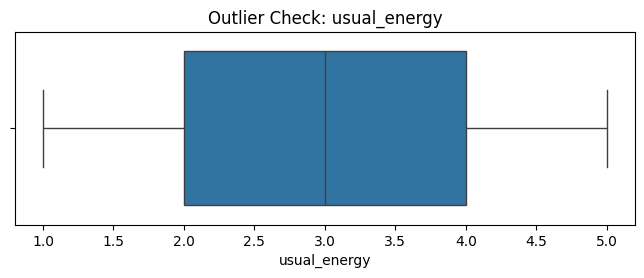

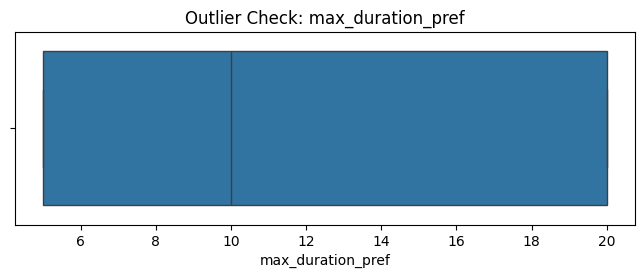

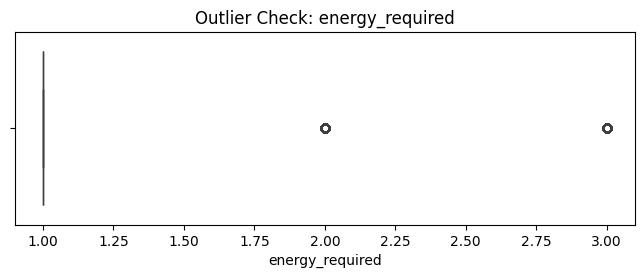

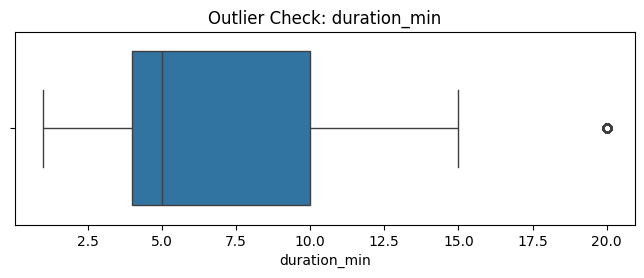

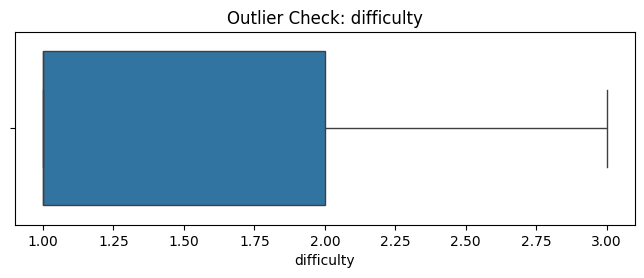

In [31]:
num_check_cols = [
    "mood_intensity", "energy_level", "usual_energy",
    "max_duration_pref", "energy_required", "duration_min", "difficulty"
]
for col in num_check_cols:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df[col])
    plt.title("Outlier Check: " + col)
    plt.show()

In [32]:
outlier_results = []
for col in num_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

           Column  Lower Bound  Upper Bound  Flagged Values
   mood_intensity         -1.0          7.0               0
     energy_level         -1.0          7.0               0
     usual_energy         -1.0          7.0               0
max_duration_pref        -17.5         42.5               0
  energy_required          1.0          1.0            3909
     duration_min         -5.0         19.0            1029
       difficulty         -0.5          3.5               0


energy_required (energy 2-3 wali activities) and duration_min (lambi activities)   asli categories ho skti hai, galat data nahi most pobably

In [33]:
print("Minimum mood intensity:", df["mood_intensity"].min())
print("Maximum mood intensity:", df["mood_intensity"].max())
print("Minimum energy level:", df["energy_level"].min())
print("Maximum energy level:", df["energy_level"].max())

Minimum mood intensity: 1
Maximum mood intensity: 5
Minimum energy level: 1
Maximum energy level: 5


Naye features

In [34]:
print(df.groupby("split")["timestamp"].agg(["min", "max", "count"]))

                    min               max  count
split                                           
test   2026-09-11 00:10  2026-09-28 23:54   3623
train  2026-07-01 00:39  2026-09-11 00:00  14492


In [35]:
df = df.sort_values(["timestamp", "interaction_id"]).reset_index(drop=True)
print(df[["timestamp", "user_id", "mood", "helpful"]].head(3))

          timestamp user_id         mood  helpful
0  2026-07-01 00:39   U0424      anxiety        1
1  2026-07-01 00:43   U0250      anxiety        0
2  2026-07-01 01:34   U0222  frustration        0


checking kaunsi cheezein helpful rate badalti hain.

In [36]:
same_mood = df["target_moods"].str.split(";").str[0] == df["mood"]
print("Activity ka main mood = user ka mood:")
print(df.groupby(same_mood)["helpful"].mean().round(3))

Activity ka main mood = user ka mood:
False    0.14
True     0.50
Name: helpful, dtype: float64


In [37]:
too_long = df["duration_min"] > df["max_duration_pref"]
print("Activity user ke max time se lambi:")
print(df.groupby(too_long)["helpful"].mean().round(3))

Activity user ke max time se lambi:
False    0.278
True     0.086
Name: helpful, dtype: float64


In [38]:
heavy = (df["energy_level"] <= 2) & (df["energy_required"] >= 2)
print("Energy low aur activity heavy:")
print(df.groupby(heavy)["helpful"].mean().round(3))

Energy low aur activity heavy:
False    0.269
True     0.038
Name: helpful, dtype: float64


In [39]:
beginner_hard = (df["experience_level"] == "beginner") & (df["difficulty"] >= 2)
print("Beginner user aur difficult activity:")
print(df.groupby(beginner_hard)["helpful"].mean().round(3))

Beginner user aur difficult activity:
False    0.271
True     0.119
Name: helpful, dtype: float64


In [40]:
first_mood = df["target_moods"].str.split(";").str[0]
df["mood_is_main"] = (first_mood == df["mood"]).astype(int)
df["mood_is_target"] = [int(m in t.split(";")) for m, t in zip(df["mood"], df["target_moods"])]
df["cat_is_pref"] = np.where(
    df["activity_category"] == df["pref_category_1"], 2,
    np.where(df["activity_category"] == df["pref_category_2"], 1, 0)
)
df["too_long"] = (df["duration_min"] > df["max_duration_pref"]).astype(int)
df["heavy_on_low_energy"] = ((df["energy_level"] <= 2) & (df["energy_required"] >= 2)).astype(int)
df["beginner_hard"] = ((df["experience_level"] == "beginner") & (df["difficulty"] >= 2)).astype(int)

In [41]:
new_features = ["mood_is_main", "mood_is_target", "cat_is_pref", "too_long", "heavy_on_low_energy", "beginner_hard"]
print(df[new_features].mean().round(3))

mood_is_main           0.301
mood_is_target         0.681
cat_is_pref            0.332
too_long               0.154
heavy_on_low_energy    0.088
beginner_hard          0.149
dtype: float64


In [42]:
old_part = df[df["split"] == "train"]
new_part = df[df["split"] == "test"]
a = old_part.groupby("user_id")["helpful"].mean()
b = new_part.groupby("user_id")["helpful"].mean()
both = pd.concat([a, b], axis=1, keys=["train", "test"]).dropna()
print("User level correlation:", round(both.corr().iloc[0, 1], 3))

User level correlation: -0.06


In [43]:
a = old_part.groupby(["user_id", "activity_category"])["helpful"].mean()
b = new_part.groupby(["user_id", "activity_category"])["helpful"].mean()
both = pd.concat([a, b], axis=1, keys=["train", "test"]).dropna()
print("User + category correlation:", round(both.corr().iloc[0, 1], 3))

User + category correlation: 0.111


In [44]:
prior = df[df["split"] == "train"]["helpful"].mean()
K = 2
print("Default helpful rate for new users:", round(prior, 3))

Default helpful rate for new users: 0.249


In [45]:
user_group = df.groupby("user_id")
df["user_past_count"] = user_group.cumcount()
df["user_past_rate"] = (
    (user_group["helpful"].cumsum() - df["helpful"]) + prior * K
) / (df["user_past_count"] + K)

In [46]:
user_cat_group = df.groupby(["user_id", "activity_category"])
df["user_cat_past_rate"] = (
    (user_cat_group["helpful"].cumsum() - df["helpful"]) + prior * K
) / (user_cat_group.cumcount() + K)

In [47]:
one_user = df[df["user_id"] == df["user_id"].iloc[0]]
print(one_user[["timestamp", "activity_category", "helpful", "user_past_count", "user_past_rate"]].head(6))

             timestamp activity_category  helpful  user_past_count  \
0     2026-07-01 00:39         grounding        1                0   
318   2026-07-02 17:43        journaling        0                1   
961   2026-07-05 21:03        journaling        0                2   
3180  2026-07-16 22:50          movement        0                3   
3518  2026-07-18 20:09        journaling        0                4   
3812  2026-07-20 07:18          movement        1                5   

      user_past_rate  
0           0.249241  
318         0.499494  
961         0.374620  
3180        0.299696  
3518        0.249747  
3812        0.214069  


In [48]:
cat_cols = [
    "mood", "time_of_day", "age_group", "experience_level",
    "pref_category_1", "pref_category_2", "activity_category"
]
num_cols = [
    "mood_intensity", "energy_level", "usual_energy", "max_duration_pref",
    "energy_required", "duration_min", "difficulty", "needs_privacy",
    "mood_is_main", "mood_is_target", "cat_is_pref", "too_long",
    "heavy_on_low_energy", "beginner_hard",
    "user_past_count", "user_past_rate", "user_cat_past_rate"
]

In [49]:
print("Numerical columns:", num_cols)
print()
print("Categorical columns:", cat_cols)

Numerical columns: ['mood_intensity', 'energy_level', 'usual_energy', 'max_duration_pref', 'energy_required', 'duration_min', 'difficulty', 'needs_privacy', 'mood_is_main', 'mood_is_target', 'cat_is_pref', 'too_long', 'heavy_on_low_energy', 'beginner_hard', 'user_past_count', 'user_past_rate', 'user_cat_past_rate']

Categorical columns: ['mood', 'time_of_day', 'age_group', 'experience_level', 'pref_category_1', 'pref_category_2', 'activity_category']


In [50]:
X = df[cat_cols + num_cols]
y = df["helpful"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (18115, 24)
Target shape: (18115,)


In [51]:
train_mask = df["split"] == "train"
X_train = X[train_mask].reset_index(drop=True)
y_train = y[train_mask].reset_index(drop=True)
X_test = X[~train_mask].reset_index(drop=True)
y_test = y[~train_mask].reset_index(drop=True)
train_df = df[train_mask].reset_index(drop=True)
test_df = df[~train_mask].reset_index(drop=True)

In [52]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Train time:", train_df["timestamp"].min(), "to", train_df["timestamp"].max())
print("Test time:", test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Training rows: 14492
Testing rows: 3623
Train time: 2026-07-01 00:39 to 2026-09-11 00:00
Test time: 2026-09-11 00:10 to 2026-09-28 23:54


In [53]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

In [54]:
tscv = TimeSeriesSplit(n_splits=4)
fold_rows = []
fold_number = 1
for train_idx, val_idx in tscv.split(X_train):
    fold_rows.append({
        "Fold": fold_number,
        "Train rows": len(train_idx),
        "Validation rows": len(val_idx),
        "Validation from": train_df.loc[val_idx[0], "timestamp"],
        "Validation to": train_df.loc[val_idx[-1], "timestamp"],
        "Helpful rate (%)": round(y_train.iloc[val_idx].mean() * 100, 2)
    })
    fold_number = fold_number + 1
print(pd.DataFrame(fold_rows).to_string(index=False))

 Fold  Train rows  Validation rows  Validation from    Validation to  Helpful rate (%)
    1        2900             2898 2026-07-15 17:32 2026-07-30 11:53             24.50
    2        5798             2898 2026-07-30 11:53 2026-08-13 19:58             25.74
    3        8696             2898 2026-08-13 20:07 2026-08-27 20:39             24.40
    4       11594             2898 2026-08-27 20:44 2026-09-11 00:00             23.81


In [55]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [56]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [57]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [58]:
print("Unique values in categorical columns:")
print(X_train[cat_cols].nunique())
print()
print(X_train[num_cols].agg(["min", "max"]).T)

Unique values in categorical columns:
mood                 8
time_of_day          4
age_group            4
experience_level     2
pref_category_1      9
pref_category_2      9
activity_category    9
dtype: int64

                          min         max
mood_intensity       1.000000    5.000000
energy_level         1.000000    5.000000
usual_energy         1.000000    5.000000
max_duration_pref    5.000000   20.000000
energy_required      1.000000    3.000000
duration_min         1.000000   20.000000
difficulty           1.000000    3.000000
needs_privacy        0.000000    1.000000
mood_is_main         0.000000    1.000000
mood_is_target       0.000000    1.000000
cat_is_pref          0.000000    2.000000
too_long             0.000000    1.000000
heavy_on_low_energy  0.000000    1.000000
beginner_hard        0.000000    1.000000
user_past_count      0.000000  151.000000
user_past_rate       0.019939    0.849848
user_cat_past_rate   0.031155    0.849848


In [59]:
seed_aucs = []
for seed in [1, 2, 3, 4, 5]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced_subsample",
            random_state=seed,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    seed_aucs.append(float(round(scores["test_score"].mean() * 100, 2)))
print("Validation AUC (%) with different seeds:", seed_aucs)

Validation AUC (%) with different seeds: [83.41, 83.39, 83.38, 83.44, 83.5]


In [60]:
noise = round(max(seed_aucs) - min(seed_aucs), 2)
tolerance = max(noise, 0.10)
print("Noise (max - min):", noise)
print("Tolerance used from now on:", tolerance)

Noise (max - min): 0.12
Tolerance used from now on: 0.12


In [61]:
scaler_results = []
for name, scaler in [("With StandardScaler", StandardScaler()), ("Without StandardScaler", "passthrough")]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", scaler, num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    scaler_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(scaler_results).to_string(index=False))

               Setting  Validation AUC (%)
   With StandardScaler               84.61
Without StandardScaler               84.62


In [62]:
from sklearn.preprocessing import OrdinalEncoder
encoder_results = []
for name, encoder in [
    ("OneHotEncoder", OneHotEncoder(handle_unknown="ignore")),
    ("OrdinalEncoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", StandardScaler(), num_cols),
            ("cat", encoder, cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    encoder_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(encoder_results).to_string(index=False))

       Setting  Validation AUC (%)
 OneHotEncoder               84.61
OrdinalEncoder               84.67


In [63]:
base_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
fold_check_results = []
for n in [3, 4, 5, 6]:
    scores = cross_validate(base_pipeline, X_train, y_train, cv=TimeSeriesSplit(n_splits=n), scoring="roc_auc")
    fold_check_results.append({"Folds": n, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(fold_check_results).to_string(index=False))

 Folds  Validation AUC (%)
     3               84.41
     4               84.61
     5               84.51
     6               84.54


In [64]:
base_feature_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
scores = cross_validate(base_feature_pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
base_feature_auc = round(scores["test_score"].mean() * 100, 2)
print("Validation AUC (%) with all features:", base_feature_auc)
print("Tolerance:", tolerance)

Validation AUC (%) with all features: 84.61
Tolerance: 0.12


In [65]:
check_features = [
    "mood_is_main", "mood_is_target", "cat_is_pref", "too_long",
    "heavy_on_low_energy", "beginner_hard",
    "user_past_count", "user_past_rate", "user_cat_past_rate"
]
feature_drop_results = []
for feature in check_features:
    num_list = [c for c in num_cols if c != feature]
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", StandardScaler(), num_list),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train[cat_cols + num_list], y_train, cv=tscv, scoring="roc_auc")
    auc_without = round(scores["test_score"].mean() * 100, 2)
    feature_drop_results.append({
        "Feature": feature,
        "AUC without it (%)": auc_without,
        "AUC drop (%)": round(base_feature_auc - auc_without, 2)
    })
feature_drop_df = pd.DataFrame(feature_drop_results).sort_values("AUC drop (%)", ascending=False)
print(feature_drop_df.to_string(index=False))

            Feature  AUC without it (%)  AUC drop (%)
     mood_is_target               80.79          3.82
       mood_is_main               81.70          2.91
        cat_is_pref               83.02          1.59
           too_long               84.04          0.57
heavy_on_low_energy               84.20          0.41
      beginner_hard               84.43          0.18
     user_past_rate               84.62         -0.01
 user_cat_past_rate               84.62         -0.01
    user_past_count               84.68         -0.07


Pehle 6 features ke hatane se AUC tolerance se zyada girta hai (0.18 se 3.82), isliye woh sab zaroori hain. Past feedback wale 3 features ka asar lagbhag zero hai.

In [66]:
past_features = ["user_past_count", "user_past_rate", "user_cat_past_rate"]
num_list = [c for c in num_cols if c not in past_features]
pipeline = Pipeline([
    ("preprocessing", ColumnTransformer([
        ("num", StandardScaler(), num_list),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
scores = cross_validate(pipeline, X_train[cat_cols + num_list], y_train, cv=tscv, scoring="roc_auc")
print("Validation AUC (%) with past feedback features:", base_feature_auc)
print("Validation AUC (%) without all 3 past feedback features:", round(scores["test_score"].mean() * 100, 2))

Validation AUC (%) with past feedback features: 84.61
Validation AUC (%) without all 3 past feedback features: 84.69


In [67]:
k_results = []
for k_value in [1, 2, 5, 10, 20, 50]:
    temp_df = df.copy()
    temp_group = temp_df.groupby("user_id")
    temp_df["user_past_count"] = temp_group.cumcount()
    temp_df["user_past_rate"] = (
        (temp_group["helpful"].cumsum() - temp_df["helpful"]) + prior * k_value
    ) / (temp_df["user_past_count"] + k_value)
    temp_cat_group = temp_df.groupby(["user_id", "activity_category"])
    temp_df["user_cat_past_rate"] = (
        (temp_cat_group["helpful"].cumsum() - temp_df["helpful"]) + prior * k_value
    ) / (temp_cat_group.cumcount() + k_value)
    X_temp = temp_df[train_mask][cat_cols + num_cols].reset_index(drop=True)
    scores = cross_validate(base_feature_pipeline, X_temp, y_train, cv=tscv, scoring="roc_auc")
    k_results.append({"K": k_value, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(k_results).to_string(index=False))

 K  Validation AUC (%)
 1               84.61
 2               84.61
 5               84.62
10               84.62
20               84.61
50               84.61


K badalne se AUC nahi badla (84.61 se 84.62). K = 2 theek hai.

ML model se pehle 2 simple baselines dekhte hain. ML ko inse behtar hona chahiye.

In [68]:
from google.colab import files
uploaded = files.upload()

Saving mood_activity_rules.csv to mood_activity_rules.csv


In [69]:
rules = pd.read_csv("mood_activity_rules.csv")
print(rules.head(6))

      mood  priority     category
0   stress         1    breathing
1   stress         2  mindfulness
2   stress         3     movement
3  anxiety         1    grounding
4  anxiety         2    breathing
5  anxiety         3  mindfulness


In [70]:
val_rows = np.concatenate([val_idx for train_idx, val_idx in tscv.split(X_train)])
y_val_rows = y_train.iloc[val_rows]
print("Total validation rows:", len(val_rows))

Total validation rows: 11592


In [71]:
rule_train = train_df.merge(
    rules,
    left_on=["mood", "activity_category"],
    right_on=["mood", "category"],
    how="left"
)
rule_pred = (rule_train["priority"] == 1).astype(int).iloc[val_rows]
print("Rows where activity was priority-1 category:", round(rule_pred.mean() * 100, 2), "%")

Rows where activity was priority-1 category: 30.09 %


In [72]:
baseline_results = []
baseline_predictions = {
    "Always 0": np.zeros(len(y_val_rows), dtype=int),
    "Rule-based (priority 1)": rule_pred.values
}
for name, y_pred in baseline_predictions.items():
    baseline_results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_val_rows, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_val_rows, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_val_rows, y_pred, zero_division=0) * 100, 2),
        "F1 Score (%)": round(f1_score(y_val_rows, y_pred, zero_division=0) * 100, 2)
    })
baseline_df = pd.DataFrame(baseline_results)
print(baseline_df.to_string(index=False))

                  Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
               Always 0         75.39           0.00        0.00          0.00
Rule-based (priority 1)         66.93          35.95       43.95         39.55


'Always 0' ki accuracy zyada hai par precision aur recall 0 hain. Isliye sirf accuracy par bharosa nahi karenge.



Model Comparison

In [73]:
candidate_models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

In [74]:
compare_results = []
for name, model in candidate_models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=tscv,
        scoring={
            "auc": "roc_auc",
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        return_train_score=True
    )
    compare_results.append({
        "Model": name,
        "Train AUC (%)": round(scores["train_auc"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_auc"].mean() * 100, 2),
        "Accuracy (%)": round(scores["test_accuracy"].mean() * 100, 2),
        "Precision (%)": round(scores["test_precision"].mean() * 100, 2),
        "Recall (%)": round(scores["test_recall"].mean() * 100, 2),
        "F1 Score (%)": round(scores["test_f1"].mean() * 100, 2)
    })
compare_df = pd.DataFrame(compare_results)
compare_df = compare_df.sort_values(
    by="Validation AUC (%)",
    ascending=False
)
print("Validation Model Comparison (default settings):")
print(compare_df.to_string(index=False))

Validation Model Comparison (default settings):
              Model  Train AUC (%)  Validation AUC (%)  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
Logistic Regression          85.51               84.61         79.49          61.13       46.74         52.82
      Random Forest         100.00               83.35         78.86          60.69       40.49         48.47
                KNN          90.65               77.82         77.37          55.00       44.39         49.08
      Decision Tree         100.00               64.17         72.48          44.57       47.75         46.01


In [75]:
print("Best Model by validation AUC:", compare_df.iloc[0]["Model"])
print("Second Best Model:", compare_df.iloc[1]["Model"])

Best Model by validation AUC: Logistic Regression
Second Best Model: Random Forest


In [76]:
knn_results = []
for neighbors in [5, 30, 100, 200, 400]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=neighbors))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    knn_results.append({"n_neighbors": neighbors, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
knn_df = pd.DataFrame(knn_results)
print(knn_df.to_string(index=False))

 n_neighbors  Validation AUC (%)
           5               77.82
          30               82.87
         100               83.79
         200               83.89
         400               84.01


In [77]:
dt_results = []
for depth in [3, 4, 6, 8, 10, 12]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    dt_results.append({"max_depth": depth, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
dt_df = pd.DataFrame(dt_results)
print(dt_df.to_string(index=False))

 max_depth  Validation AUC (%)
         3               80.95
         4               82.16
         6               82.84
         8               82.09
        10               81.72
        12               81.16


In [78]:
lr_default_auc = compare_df[compare_df["Model"] == "Logistic Regression"]["Validation AUC (%)"].iloc[0]
print("Best KNN validation AUC (%):", knn_df["Validation AUC (%)"].max())
print("Best Decision Tree validation AUC (%):", dt_df["Validation AUC (%)"].max())
print("Logistic Regression (default) validation AUC (%):", lr_default_auc)

Best KNN validation AUC (%): 84.01
Best Decision Tree validation AUC (%): 82.84
Logistic Regression (default) validation AUC (%): 84.61


Tune karne ke baad bhi KNN (84.01) aur Decision Tree (82.84) Logistic Regression (84.61) se peeche hain.

In [80]:
import warnings
import joblib
import os

In [81]:
for iterations in [100, 1000]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(max_iter=iterations, random_state=42))
    ])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipeline.fit(X_train, y_train)
    print("max_iter =", iterations, "| convergence warnings:", len(caught))

max_iter = 100 | convergence warnings: 1
max_iter = 1000 | convergence warnings: 2


In [83]:
from sklearn.exceptions import ConvergenceWarning

for iterations in [100, 1000]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(max_iter=iterations, random_state=42))
    ])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipeline.fit(X_train, y_train)
    convergence = [w for w in caught if issubclass(w.category, ConvergenceWarning)]
    print("max_iter =", iterations, "| convergence warnings:", len(convergence), "| other warnings:", len(caught) - len(convergence))
    for w in caught:
        print("    ", w.category.__name__, "-", str(w.message)[:100])

max_iter = 100 | convergence warnings: 0 | other warnings: 1
     DeprecationWarning - scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be re
max_iter = 1000 | convergence warnings: 0 | other warnings: 2
     DeprecationWarning - scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be re
     DeprecationWarning - datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone


setting class weight

In [84]:
lr_weight_options = [None, "balanced"]
cw_results = []
for weight in lr_weight_options:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight=weight,
            random_state=42
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring={"auc": "roc_auc", "precision": "precision", "recall": "recall"}
    )
    cw_results.append({
        "class_weight": str(weight),
        "Validation AUC (%)": round(scores["test_auc"].mean() * 100, 2),
        "Precision (%)": round(scores["test_precision"].mean() * 100, 2),
        "Recall (%)": round(scores["test_recall"].mean() * 100, 2)
    })
cw_df = pd.DataFrame(cw_results)
print(cw_df.to_string(index=False))

class_weight  Validation AUC (%)  Precision (%)  Recall (%)
        None               84.61          61.13       46.74
    balanced               84.60          50.85       77.28


In [85]:
best_index = cw_df["Validation AUC (%)"].idxmax()
if cw_df.loc[best_index, "Validation AUC (%)"] >= cw_df.loc[0, "Validation AUC (%)"] + tolerance:
    best_lr_weight = lr_weight_options[best_index]
else:
    best_lr_weight = None
print("Chosen class_weight:", best_lr_weight)

Chosen class_weight: None


balanced se recall badhta hai par precision girta hai

c= simple model   C = complex model

In [86]:
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
c_results = []
for c in c_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            C=c,
            max_iter=1000,
            class_weight=best_lr_weight,
            random_state=42
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    c_results.append({
        "C": c,
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
c_df = pd.DataFrame(c_results)
print(c_df.to_string(index=False))

      C  Train AUC (%)  Validation AUC (%)
  0.001          84.41               84.46
  0.010          85.24               84.75
  0.100          85.49               84.70
  1.000          85.51               84.61
 10.000          85.52               84.59
100.000          85.52               84.59


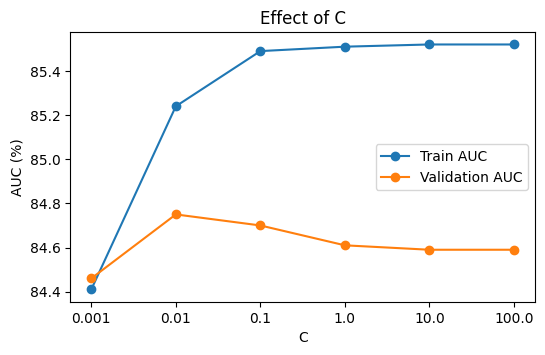

In [87]:
plt.figure(figsize=(6, 3.5))
plt.plot(c_df["C"].astype(str), c_df["Train AUC (%)"], marker="o", label="Train AUC")
plt.plot(c_df["C"].astype(str), c_df["Validation AUC (%)"], marker="o", label="Validation AUC")
plt.xlabel("C")
plt.ylabel("AUC (%)")
plt.title("Effect of C")
plt.legend()
plt.show()

In [88]:
best_c_auc = c_df["Validation AUC (%)"].max()
close_c = c_df[c_df["Validation AUC (%)"] >= best_c_auc - tolerance]
print("Best Validation AUC (%):", best_c_auc)
print("Values within tolerance (simple se complex):")
print(close_c.to_string(index=False))
best_c = close_c.iloc[0]["C"]
print("Chosen C:", best_c)

Best Validation AUC (%): 84.75
Values within tolerance (simple se complex):
   C  Train AUC (%)  Validation AUC (%)
0.01          85.24               84.75
0.10          85.49               84.70
Chosen C: 0.01


best AUC ke tolerance ke andar jo sabse simple (chhota C) hai wahi chuna.

trying at penalty 11  bhi default 12 hai

In [90]:
l1_values = [0.003, 0.01, 0.03, 0.1, 0.3, 1]
l1_results = []
for c in l1_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=c,
            max_iter=1000,
            class_weight=best_lr_weight,
            random_state=42
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    l1_results.append({"C": c, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
l1_df = pd.DataFrame(l1_results)
print(l1_df.to_string(index=False))

    C  Validation AUC (%)
0.003               81.28
0.010               84.20
0.030               84.65
0.100               84.86
0.300               84.77
1.000               84.66


In [91]:
l2_auc = c_df.loc[c_df["C"] == best_c, "Validation AUC (%)"].iloc[0]
best_l1_auc = l1_df["Validation AUC (%)"].max()
close_l1 = l1_df[l1_df["Validation AUC (%)"] >= best_l1_auc - tolerance]
l1_auc = close_l1.iloc[0]["Validation AUC (%)"]
print("l2 (C =", best_c, ") validation AUC (%):", l2_auc)
print("l1 (C =", close_l1.iloc[0]["C"], ") validation AUC (%):", l1_auc)
print("Difference:", round(l1_auc - l2_auc, 2), "| Tolerance:", tolerance)
if l1_auc >= l2_auc + tolerance:
    print("l1 behtar hai")
else:
    print("Farq tolerance se chhota hai, isliye default l2 rakhenge")

l2 (C = 0.01 ) validation AUC (%): 84.75
l1 (C = 0.1 ) validation AUC (%): 84.86
Difference: 0.11 | Tolerance: 0.12
Farq tolerance se chhota hai, isliye default l2 rakhenge


Farq 0.11 hai, tolerance 0.12 se bas thoda chhota. Isliye default l2 hi rakha.

StandardScaler

In [92]:
scaler8_results = []
for name, scaler in [("With StandardScaler", StandardScaler()), ("Without StandardScaler", "passthrough")]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", scaler, num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])),
        ("model", LogisticRegression(
            C=best_c,
            max_iter=2000,
            class_weight=best_lr_weight,
            random_state=42
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    scaler8_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(scaler8_results).to_string(index=False))

               Setting  Validation AUC (%)
   With StandardScaler               84.75
Without StandardScaler               84.20


Chune hue C par scaling ke bina AUC 0.55 kam hai (tolerance se zyada). Isliye StandardScaler zaroori hai.

ONE HOT ENCODER

In [93]:
encoder8_results = []
for name, encoder in [
    ("OneHotEncoder", OneHotEncoder(handle_unknown="ignore")),
    ("OrdinalEncoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", StandardScaler(), num_cols),
            ("cat", encoder, cat_cols)
        ])),
        ("model", LogisticRegression(
            C=best_c,
            max_iter=2000,
            class_weight=best_lr_weight,
            random_state=42
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    encoder8_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(encoder8_results).to_string(index=False))

       Setting  Validation AUC (%)
 OneHotEncoder               84.75
OrdinalEncoder               84.67


In [94]:
lr_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        C=best_c,
        max_iter=1000,
        class_weight=best_lr_weight,
        random_state=42
    ))
])
print("Logistic Regression final settings: C =", best_c, ", max_iter = 1000, class_weight =", best_lr_weight)

Logistic Regression final settings: C = 0.01 , max_iter = 1000, class_weight = None


RANDOM FOREST TUNING

In [95]:
depth_values = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
depth_results = []
for depth in depth_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=depth,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    depth_results.append({
        "max_depth": str(depth),
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
depth_df = pd.DataFrame(depth_results)
print(depth_df.to_string(index=False))

max_depth  Train AUC (%)  Validation AUC (%)
        2          83.35               83.25
        3          84.30               83.90
        4          84.79               83.92
        5          85.75               84.25
        6          86.72               84.11
        8          89.77               84.05
       10          93.38               83.97
       12          96.54               83.80
       15          99.30               83.71
       20         100.00               83.39
     None         100.00               83.56


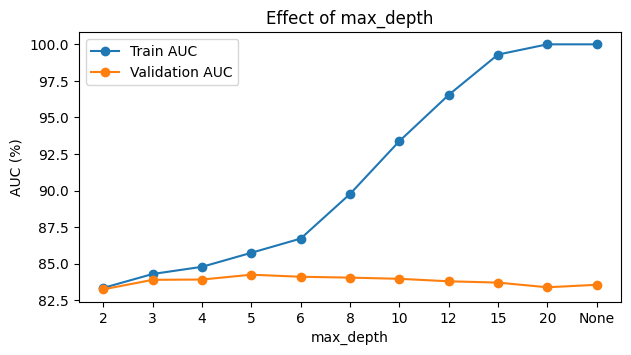

In [96]:
plt.figure(figsize=(7, 3.5))
plt.plot(depth_df["max_depth"], depth_df["Train AUC (%)"], marker="o", label="Train AUC")
plt.plot(depth_df["max_depth"], depth_df["Validation AUC (%)"], marker="o", label="Validation AUC")
plt.xlabel("max_depth")
plt.ylabel("AUC (%)")
plt.title("Effect of max_depth")
plt.legend()
plt.show()

Train AUC badhta rehta hai par validation ek jagah ke baad girne lagta hai. overfitting hai (tree ratta maar raha hai).

In [97]:
leaf_values = [50, 20, 10, 5, 2, 1]
leaf_results = []
for leaf in leaf_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=leaf,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    leaf_results.append({
        "min_samples_leaf": leaf,
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
leaf_df = pd.DataFrame(leaf_results)
print(leaf_df.to_string(index=False))

 min_samples_leaf  Train AUC (%)  Validation AUC (%)
               50          86.01               84.27
               20          88.46               84.47
               10          91.22               84.43
                5          95.15               84.37
                2          99.74               84.22
                1         100.00               83.56


depth + leaf saath mein.

In [98]:
d_grid = [3, 5, 8, 12, None]
l_grid = [1, 5, 10, 20, 50]
grid_results = []
for depth in d_grid:
    for leaf in l_grid:
        pipeline = Pipeline([
            ("preprocessing", preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=100,
                max_depth=depth,
                min_samples_leaf=leaf,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            ))
        ])
        scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
        grid_results.append({
            "max_depth": str(depth),
            "min_samples_leaf": leaf,
            "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
        })
grid_df = pd.DataFrame(grid_results)
grid_pivot = grid_df.pivot(
    index="max_depth",
    columns="min_samples_leaf",
    values="Validation AUC (%)"
)
grid_pivot = grid_pivot.loc[[str(d) for d in d_grid]]
print(grid_pivot)

min_samples_leaf     1      5      10     20     50
max_depth                                          
3                 83.90  83.90  83.90  83.89  83.86
5                 84.25  84.26  84.21  84.22  84.12
8                 84.05  84.25  84.35  84.37  84.27
12                83.80  84.26  84.47  84.39  84.29
None              83.56  84.37  84.43  84.47  84.27


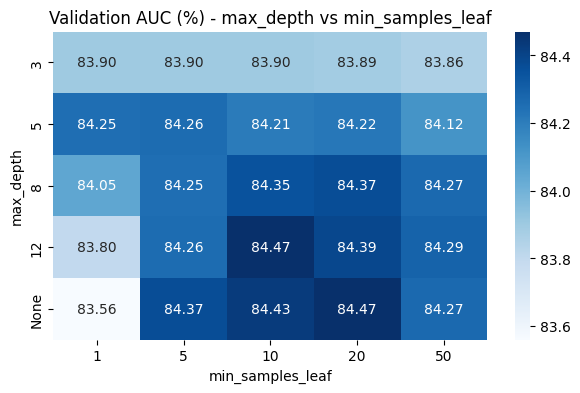

In [99]:
plt.figure(figsize=(7, 4))
sns.heatmap(grid_pivot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Validation AUC (%) - max_depth vs min_samples_leaf")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.show()

In [100]:
best_grid_auc = grid_df["Validation AUC (%)"].max()
close_grid = grid_df[grid_df["Validation AUC (%)"] >= best_grid_auc - tolerance].copy()
close_grid["depth_order"] = close_grid["max_depth"].map(lambda d: 99 if d == "None" else int(d))
close_grid = close_grid.sort_values(
    ["depth_order", "min_samples_leaf"],
    ascending=[True, False]
)
print("Best Validation AUC (%):", best_grid_auc)
print("Combinations within tolerance:")
print(close_grid[["max_depth", "min_samples_leaf", "Validation AUC (%)"]].to_string(index=False))

Best Validation AUC (%): 84.47
Combinations within tolerance:
max_depth  min_samples_leaf  Validation AUC (%)
        8                20               84.37
        8                10               84.35
       12                20               84.39
       12                10               84.47
     None                20               84.47
     None                10               84.43
     None                 5               84.37


In [101]:
best_depth_text = close_grid.iloc[0]["max_depth"]
best_depth = None if best_depth_text == "None" else int(best_depth_text)
best_leaf = int(close_grid.iloc[0]["min_samples_leaf"])
print("Chosen max_depth:", best_depth)
print("Chosen min_samples_leaf:", best_leaf)

Chosen max_depth: 8
Chosen min_samples_leaf: 20


CHECKING CLASS WEIGHT AGAIN

In [102]:
cw_options = [None, "balanced", "balanced_subsample"]
rf_cw_results = []
for weight in cw_options:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            class_weight=weight,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring={"auc": "roc_auc", "precision": "precision", "recall": "recall"}
    )
    rf_cw_results.append({
        "class_weight": str(weight),
        "Validation AUC (%)": round(scores["test_auc"].mean() * 100, 2),
        "Precision (%)": round(scores["test_precision"].mean() * 100, 2),
        "Recall (%)": round(scores["test_recall"].mean() * 100, 2)
    })
rf_cw_df = pd.DataFrame(rf_cw_results)
print(rf_cw_df.to_string(index=False))

      class_weight  Validation AUC (%)  Precision (%)  Recall (%)
              None               84.55          67.06       26.56
          balanced               84.35          48.95       79.06
balanced_subsample               84.37          48.95       79.30


In [103]:
base_auc = rf_cw_df.loc[rf_cw_df["class_weight"] == "balanced_subsample", "Validation AUC (%)"].iloc[0]
best_index = rf_cw_df["Validation AUC (%)"].idxmax()
print("Ab tak ki setting (balanced_subsample) ka validation AUC (%):", base_auc)
print("Badlav ke liye chahiye kam se kam:", round(base_auc + tolerance, 2))
if rf_cw_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_cw = cw_options[best_index]
    base_auc = rf_cw_df.loc[best_index, "Validation AUC (%)"]
else:
    best_cw = "balanced_subsample"
print("Chosen class_weight:", best_cw)

Ab tak ki setting (balanced_subsample) ka validation AUC (%): 84.37
Badlav ke liye chahiye kam se kam: 84.49
Chosen class_weight: None


Bina weight ke AUC tolerance se zyada hai, isliye None chuna

In [104]:
print("Ab tak ki setting ka validation AUC (%):", base_auc)
print("Badlav ke liye chahiye kam se kam:", round(base_auc + tolerance, 2))

Ab tak ki setting ka validation AUC (%): 84.55
Badlav ke liye chahiye kam se kam: 84.67


In [105]:
split_values = [100, 50, 20, 10, 5, 2]
split_results = []
for split in split_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=split,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    split_results.append({
        "min_samples_split": split,
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
split_df = pd.DataFrame(split_results)
print(split_df.to_string(index=False))

 min_samples_split  Train AUC (%)  Validation AUC (%)
               100          86.24               84.48
                50          86.69               84.54
                20          86.72               84.55
                10          86.72               84.55
                 5          86.72               84.55
                 2          86.72               84.55


In [106]:
best_index = split_df["Validation AUC (%)"].idxmax()
if split_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_split = split_values[best_index]
    base_auc = split_df.loc[best_index, "Validation AUC (%)"]
else:
    best_split = 2
print("Chosen min_samples_split:", best_split)

Chosen min_samples_split: 2


In [107]:
mln_values = [10, 20, 40, 80, 160, None]
mln_results = []
for mln in mln_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=best_split,
            max_leaf_nodes=mln,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    mln_results.append({
        "max_leaf_nodes": str(mln),
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
mln_df = pd.DataFrame(mln_results)
print(mln_df.to_string(index=False))

max_leaf_nodes  Train AUC (%)  Validation AUC (%)
            10          84.73               84.25
            20          85.59               84.43
            40          86.39               84.51
            80          86.71               84.51
           160          86.72               84.51
          None          86.72               84.55


In [108]:
best_index = mln_df["Validation AUC (%)"].idxmax()
if mln_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_mln = mln_values[best_index]
    base_auc = mln_df.loc[best_index, "Validation AUC (%)"]
else:
    best_mln = None
print("Chosen max_leaf_nodes:", best_mln)

Chosen max_leaf_nodes: None


In [109]:
mf_values = ["log2", "sqrt", 0.3, 0.5, 1.0]
mf_results = []
for mf in mf_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=best_split,
            max_leaf_nodes=best_mln,
            max_features=mf,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    mf_results.append({
        "max_features": str(mf),
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
mf_df = pd.DataFrame(mf_results)
print(mf_df.to_string(index=False))

max_features  Train AUC (%)  Validation AUC (%)
        log2          86.54               84.42
        sqrt          86.72               84.55
         0.3          87.30               84.55
         0.5          87.49               84.30
         1.0          87.60               83.89


In [110]:
best_index = mf_df["Validation AUC (%)"].idxmax()
if mf_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_mf = mf_values[best_index]
    base_auc = mf_df.loc[best_index, "Validation AUC (%)"]
else:
    best_mf = "sqrt"
print("Chosen max_features:", best_mf)

Chosen max_features: sqrt


In [111]:
tree_values = [25, 50, 100, 200, 300, 500]
tree_results = []
for trees in tree_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=trees,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=best_split,
            max_leaf_nodes=best_mln,
            max_features=best_mf,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring="roc_auc", return_train_score=True
    )
    tree_results.append({
        "n_estimators": trees,
        "Train AUC (%)": round(scores["train_score"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)
    })
tree_df = pd.DataFrame(tree_results)
print(tree_df.to_string(index=False))

 n_estimators  Train AUC (%)  Validation AUC (%)
           25          86.57               84.18
           50          86.75               84.56
          100          86.72               84.55
          200          86.82               84.59
          300          86.84               84.61
          500          86.86               84.62


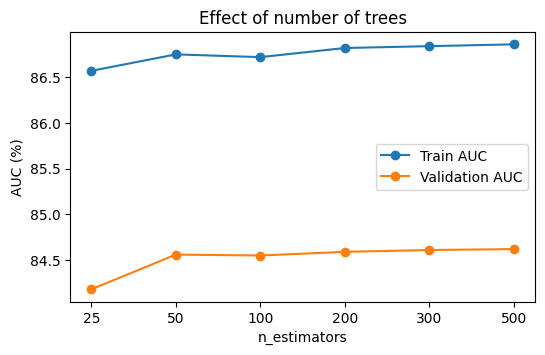

In [112]:
plt.figure(figsize=(6, 3.5))
plt.plot(tree_df["n_estimators"].astype(str), tree_df["Train AUC (%)"], marker="o", label="Train AUC")
plt.plot(tree_df["n_estimators"].astype(str), tree_df["Validation AUC (%)"], marker="o", label="Validation AUC")
plt.xlabel("n_estimators")
plt.ylabel("AUC (%)")
plt.title("Effect of number of trees")
plt.legend()
plt.show()

In [113]:
best_trees = tree_values[tree_df["Validation AUC (%)"].idxmax()]
print("Chosen n_estimators:", best_trees)

Chosen n_estimators: 500


In [114]:
base_auc = tree_df["Validation AUC (%)"].max()
criterion_values = ["gini", "entropy", "log_loss"]
criterion_results = []
for criterion in criterion_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=best_trees,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=best_split,
            max_leaf_nodes=best_mln,
            max_features=best_mf,
            criterion=criterion,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    criterion_results.append({"criterion": criterion, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
criterion_df = pd.DataFrame(criterion_results)
print(criterion_df.to_string(index=False))

criterion  Validation AUC (%)
     gini               84.62
  entropy               84.62
 log_loss               84.62


In [115]:
best_index = criterion_df["Validation AUC (%)"].idxmax()
if criterion_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_criterion = criterion_values[best_index]
    base_auc = criterion_df.loc[best_index, "Validation AUC (%)"]
else:
    best_criterion = "gini"
print("Chosen criterion:", best_criterion)

Chosen criterion: gini


bootstrap

In [116]:
bootstrap_values = [True, False]
bootstrap_results = []
for bootstrap in bootstrap_values:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=best_trees,
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            min_samples_split=best_split,
            max_leaf_nodes=best_mln,
            max_features=best_mf,
            criterion=best_criterion,
            bootstrap=bootstrap,
            class_weight=best_cw,
            random_state=42,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    bootstrap_results.append({"bootstrap": str(bootstrap), "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
bootstrap_df = pd.DataFrame(bootstrap_results)
print(bootstrap_df.to_string(index=False))

bootstrap  Validation AUC (%)
     True               84.62
    False               84.66


In [117]:
best_index = bootstrap_df["Validation AUC (%)"].idxmax()
if bootstrap_df.loc[best_index, "Validation AUC (%)"] >= base_auc + tolerance:
    best_bootstrap = bootstrap_values[best_index]
else:
    best_bootstrap = True
print("Chosen bootstrap:", best_bootstrap)

Chosen bootstrap: True


Final settings

In [119]:
rf_params = {
    "n_estimators": best_trees,
    "max_depth": best_depth,
    "min_samples_leaf": best_leaf,
    "min_samples_split": best_split,
    "max_leaf_nodes": best_mln,
    "max_features": best_mf,
    "class_weight": best_cw,
    "criterion": best_criterion,
    "bootstrap": best_bootstrap,
    "random_state": 42,
    "n_jobs": -1
}
for key, value in rf_params.items():
    print(key, "=", value)
print("Default par chhode gaye: min_impurity_decrease = 0.0, ccp_alpha = 0.0")

n_estimators = 500
max_depth = 8
min_samples_leaf = 20
min_samples_split = 2
max_leaf_nodes = None
max_features = sqrt
class_weight = None
criterion = gini
bootstrap = True
random_state = 42
n_jobs = -1
Default par chhode gaye: min_impurity_decrease = 0.0, ccp_alpha = 0.0


In [120]:
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(**rf_params))
])
default_rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [121]:
rf_compare = []
for name, pipeline in [("Default Random Forest", default_rf_pipeline), ("Tuned Random Forest", rf_pipeline)]:
    scores = cross_validate(
        pipeline, X_train, y_train, cv=tscv,
        scoring={"auc": "roc_auc", "precision": "precision", "recall": "recall"},
        return_train_score=True
    )
    rf_compare.append({
        "Model": name,
        "Train AUC (%)": round(scores["train_auc"].mean() * 100, 2),
        "Validation AUC (%)": round(scores["test_auc"].mean() * 100, 2),
        "Precision (%)": round(scores["test_precision"].mean() * 100, 2),
        "Recall (%)": round(scores["test_recall"].mean() * 100, 2)
    })
print(pd.DataFrame(rf_compare).to_string(index=False))

                Model  Train AUC (%)  Validation AUC (%)  Precision (%)  Recall (%)
Default Random Forest         100.00               83.35          60.69       40.49
  Tuned Random Forest          86.86               84.62          67.77       25.24


Final forest ka structure

In [122]:
rf_pipeline.fit(X_train, y_train)
forest = rf_pipeline.named_steps["model"]
tree_depths = [t.get_depth() for t in forest.estimators_]
tree_leaves = [t.get_n_leaves() for t in forest.estimators_]
tree_nodes = [t.tree_.node_count for t in forest.estimators_]
structure_df = pd.DataFrame({
    "Depth": tree_depths,
    "Leaves": tree_leaves,
    "Total Nodes": tree_nodes
})
print("Number of trees:", len(forest.estimators_))
print(structure_df.agg(["min", "mean", "max"]).round(1))

Number of trees: 500
      Depth  Leaves  Total Nodes
min     8.0    59.0        117.0
mean    8.0    93.3        185.6
max     8.0   131.0        261.0


In [123]:
feature_names = [
    n.replace("num__", "").replace("cat__", "")
    for n in rf_pipeline.named_steps["preprocessing"].get_feature_names_out()
]
print(export_text(forest.estimators_[0], feature_names=feature_names, max_depth=3))

|--- heavy_on_low_energy <= 1.46
|   |--- activity_category_creative <= 0.50
|   |   |--- energy_required <= 2.30
|   |   |   |--- activity_category_mindfulness <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- activity_category_mindfulness >  0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- energy_required >  2.30
|   |   |   |--- mood_restlessness <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- mood_restlessness >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- activity_category_creative >  0.50
|   |   |--- too_long <= 0.96
|   |   |   |--- mood_is_main <= 0.43
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- mood_is_main >  0.43
|   |   |   |   |--- class: 1.0
|   |   |--- too_long >  0.96
|   |   |   |--- mood_intensity <= -0.45
|   |   |   |   |--- class: 0.0
|   |   |   |--- mood_intensity >  -0.45
|   |   |   |   |--- truncated branch of depth 4
|--- heavy_on_low_energy >  1.46


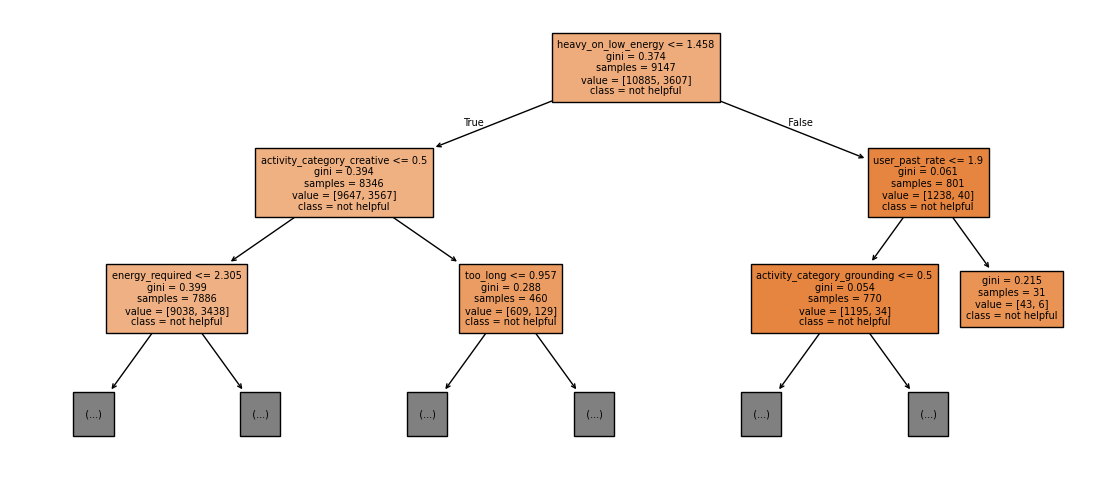

In [124]:
plt.figure(figsize=(14, 6))
plot_tree(
    forest.estimators_[0],
    feature_names=feature_names,
    max_depth=2,
    filled=True,
    fontsize=7,
    class_names=["not helpful", "helpful"]
)
plt.show()